# Assignment 3 — Module 3: Evolutionary and Swarm Optimization


## Practical 10: Complete GA Optimization System Using DEAP

### Aim
To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation, and convergence analysis.

### Theory
**DEAP** (Distributed Evolutionary Algorithms in Python) provides ready-made GA building blocks through a `Toolbox`. This practical solves the **0/1 Knapsack problem**: choose a subset of items that maximizes total value without exceeding a weight capacity.

- Individuals are binary lists (1 = item taken).
- Fitness is the total value, with a penalty for exceeding capacity.
- Operators: tournament selection, two-point crossover, bit-flip mutation.
- Convergence is tracked with DEAP's `Statistics` and `HallOfFame`, and the GA result is compared with the exact optimum from dynamic programming.

### Install and import DEAP

In [1]:
# If DEAP is missing, run in a terminal:  pip install deap
!pip install deap
import deap
print("DEAP version:", deap.__version__)

Defaulting to user installation because normal site-packages is not writeable
DEAP version: 1.4



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Problem definition

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

random.seed(42)
np.random.seed(42)

# 0/1 Knapsack instance
N_ITEMS = 20
values  = [random.randint(10, 100) for _ in range(N_ITEMS)]
weights = [random.randint(5, 50)   for _ in range(N_ITEMS)]
CAPACITY = int(sum(weights) * 0.4)
print("Capacity:", CAPACITY)
print("Total items:", N_ITEMS)

Capacity: 230
Total items: 20


### Creator and toolbox (population initialization, operators)

In [3]:
# Fitness is maximized; individuals are lists of bits
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=N_ITEMS)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def evaluate(individual):
    # Fitness evaluation with a penalty for overweight solutions
    total_w = sum(w for w, g in zip(weights, individual) if g)
    total_v = sum(v for v, g in zip(values, individual) if g)
    if total_w > CAPACITY:
        return (total_v - 10 * (total_w - CAPACITY),)   # penalty
    return (total_v,)

toolbox.register("evaluate", evaluate)
toolbox.register("select", tools.selTournament, tournsize=3)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=1.0 / N_ITEMS)

### Run the GA with statistics and hall of fame

In [4]:
pop = toolbox.population(n=100)
hof = tools.HallOfFame(1)

stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("max", np.max)
stats.register("avg", np.mean)
stats.register("min", np.min)

pop, logbook = algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2,
                                   ngen=60, stats=stats, halloffame=hof, verbose=False)

best = hof[0]
sel_items = [i for i, g in enumerate(best) if g]
print("Best fitness (value):", best.fitness.values[0])
print("Selected items      :", sel_items)
print("Total weight        :", sum(weights[i] for i in sel_items), "/", CAPACITY)

Best fitness (value): 702.0
Selected items      : [0, 2, 7, 8, 9, 11, 12, 13, 16, 17, 18, 19]
Total weight        : 228 / 230


### Convergence analysis

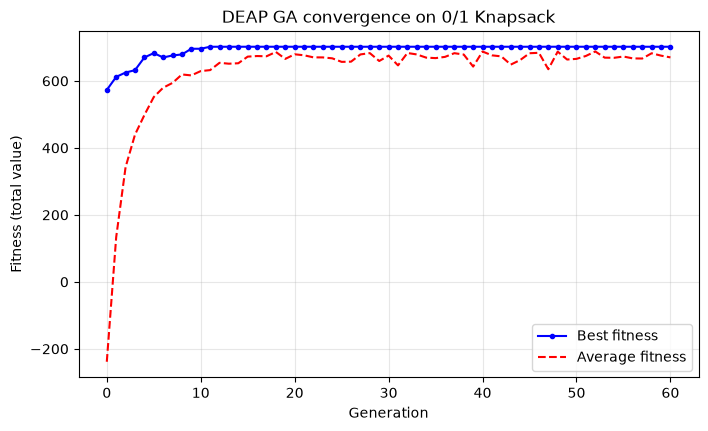

In [5]:
gen = logbook.select("gen")
max_f = logbook.select("max")
avg_f = logbook.select("avg")

plt.figure(figsize=(8, 4.5))
plt.plot(gen, max_f, 'b-o', markersize=3, label='Best fitness')
plt.plot(gen, avg_f, 'r--', label='Average fitness')
plt.xlabel('Generation'); plt.ylabel('Fitness (total value)')
plt.title('DEAP GA convergence on 0/1 Knapsack')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

### Validation against exact dynamic-programming optimum

In [6]:
def knapsack_dp(values, weights, cap):
    dp = [0] * (cap + 1)
    for v, w in zip(values, weights):
        for c in range(cap, w - 1, -1):
            dp[c] = max(dp[c], dp[c - w] + v)
    return dp[cap]

optimum = knapsack_dp(values, weights, CAPACITY)
ga_value = best.fitness.values[0]
print("Exact optimum (DP) :", optimum)
print("GA best value      :", ga_value)
print(f"GA reached {ga_value / optimum * 100:.2f}% of the optimum")

Exact optimum (DP) : 711
GA best value      : 702.0
GA reached 98.73% of the optimum


### Summary of the system

In [7]:
print("Final generation statistics:")
print(f"  max = {max_f[-1]:.0f}, avg = {avg_f[-1]:.2f}")
print("Pipeline used: initialization -> evaluation -> tournament selection -> two-point crossover -> bit-flip mutation -> elitism via HallOfFame")

Final generation statistics:
  max = 702, avg = 670.23
Pipeline used: initialization -> evaluation -> tournament selection -> two-point crossover -> bit-flip mutation -> elitism via HallOfFame


### Observation
- Best and average fitness rise over generations; the best value climbs quickly early and then plateaus as the population converges.
- The GA solution is compared with the exact dynamic-programming optimum, showing how close the evolutionary search gets.
- The penalty term steers the population away from infeasible (overweight) solutions.

### Conclusion
Built a complete DEAP-based GA system covering initialization, evaluation, selection, crossover, mutation, convergence analysis and validation against an exact solution.